<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# Tile fragments are not source features

A vector tileset can repeat buffered copies of the same road or area in neighboring tiles. We read a small archive in raw, clipped and merged modes, compare its geometry and accounting, then change the zoom level.

**These are unchanged synthetic repository fixtures.** Two invented roads and two invented areas were encoded into a PMTiles archive by the repository’s GDAL generator. Their coordinates are design inputs, not observations of real infrastructure. The source GeoJSON files, archive and byte hashes are bundled for provenance. No external basemap or live service is used.

## Choose the zoom, keep the edge policies side by side

`ZOOM` accepts **2** or **3**, default **3**. Both levels are present in the fixture. All three modes use the same selected zoom and full tileset coverage. Changing zoom changes tile boundaries and quantization; it need not preserve the exact decoded area or length.

In [1]:
ZOOM = 3  # compare the fixture at zoom 3 or zoom 2

In [2]:
import hashlib
import json
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MaxNLocator

from map_support import draw_geometry
from notebook_support import finish, theme

assert type(ZOOM) is int and ZOOM in {2, 3}
manifest = json.loads(Path("fixtures/provenance.json").read_text())
for item in manifest["files"]:
    assert hashlib.sha256((Path("fixtures") / item["file"]).read_bytes()).hexdigest() == item["sha256"]
connection = haybarn.connect()
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-mvt/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-mvt/notebooks/pyproject.toml.

## Inspect metadata and materialize each read once

The visible Git launcher pins the worker revision and its tested SDK/engine versions. Haybarn 2.0.0rc11 runs the notebook; the separate worker process uses its source-tested internal Haybarn 1.5.5rc1 for SDK filter support. These environments are intentionally separate.

The worker decodes and resolves tile edges. The Spatial extension supplies SQL geometry measurements. We explicitly request **EPSG:3857 Web Mercator coordinates**: planar area and length below are projected-coordinate measures, not geodesic ground measurements. Metadata is a declaration from the file, not a fresh count of decoded features.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL spatial;
LOAD spatial;
ATTACH 'mvt' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with haybarn==1.5.5rc1 --with pmtiles==3.8.1 --with shapely==2.2.0 --from git+https://github.com/Query-farm/vgi-mvt@41aa112e5d72f2ee7481e68c45ba6e4e03174690 vgi-mvt-worker');
CREATE TABLE metadata AS SELECT * FROM mvt.main.tileset_metadata('fixtures/edges.pmtiles');
CREATE TABLE features AS
SELECT 'raw' AS mode,* FROM mvt.main.read_tiles('fixtures/edges.pmtiles',zoom := {{ZOOM}},coordinates := 'web_mercator',tile_edges := 'raw')
UNION ALL
SELECT 'clip',* FROM mvt.main.read_tiles('fixtures/edges.pmtiles',zoom := {{ZOOM}},coordinates := 'web_mercator',tile_edges := 'clip')
UNION ALL
SELECT 'merge',* FROM mvt.main.read_tiles('fixtures/edges.pmtiles',zoom := {{ZOOM}},coordinates := 'web_mercator',tile_edges := 'merge');

,Count


In [4]:
%%sql declarations <<
SELECT * FROM metadata WHERE key IN('name','format','minzoom','maxzoom','bounds') ORDER BY key;

In [5]:
display(declarations)

,key,value
0,bounds,"-20,10,25,55"
1,format,pmtiles
2,maxzoom,3
3,minzoom,0
4,name,vgi-mvt-edges


## Count rows and preserve fixture identity

The archive has no encoded feature IDs. For this deliberately labeled fixture, `(layer, properties.name)` identifies the four source features; names are not a general substitute for IDs. Merge uses layer, properties and adjoining tile edges when IDs are absent. Disconnected pieces without suitable identity can still remain separate in real tilesets.

Raw retains buffered tile copies. Clip removes the buffer and retains tile pieces. Merge joins compatible pieces. The `z/x/y` on a merged row identifies a contributing tile, not a complete list of tiles touched by that feature.

In [6]:
%%sql
CREATE TABLE accounting AS
SELECT mode,layer,count(*) AS rows,count(DISTINCT properties->>'$.name') AS fixture_features,
 count(*) FILTER(WHERE feature_id IS NULL) AS rows_without_ids,
 sum(CASE WHEN layer='areas' THEN ST_Area(geometry) ELSE ST_Length(geometry) END) AS projected_measure
FROM features GROUP BY mode,layer;
CREATE TABLE source_keys AS
SELECT 'roads' AS layer,name
FROM ST_Read('fixtures/edges_roads.geojson')
UNION ALL
SELECT 'areas',name
FROM ST_Read('fixtures/edges_areas.geojson');

,Count


In [7]:
%%sql summary <<
SELECT a.mode,a.layer,a.rows,a.fixture_features,a.rows_without_ids,
 CASE WHEN a.layer='areas' THEN 'm² in EPSG:3857' ELSE 'm in EPSG:3857' END AS unit,
 a.projected_measure,100*a.projected_measure/m.projected_measure AS percent_of_merged
FROM accounting a JOIN accounting m ON a.layer=m.layer AND m.mode='merge'
ORDER BY CASE a.mode WHEN 'raw' THEN 1 WHEN 'clip' THEN 2 ELSE 3 END,a.layer;

In [8]:
display(summary)

,mode,layer,rows,fixture_features,rows_without_ids,unit,projected_measure,percent_of_merged
0,raw,areas,5,2,5,m² in EPSG:3857,5.313895e+12,118.756293
1,raw,roads,4,2,4,m in EPSG:3857,6.375415e+06,109.944232
2,clip,areas,5,2,5,m² in EPSG:3857,4.474621e+12,100.000000
3,clip,roads,4,2,4,m in EPSG:3857,5.799020e+06,100.004283
4,merge,areas,2,2,2,m² in EPSG:3857,4.474621e+12,100.000000
5,merge,roads,2,2,2,m in EPSG:3857,5.798771e+06,100.000000


## See the geometry and tile boundaries

All panels share bounds, scale and feature colors. Dashed lines mark tile boundaries derived from the returned tile addresses. Raw polygon shading can overlap, and line pieces can extend beyond a boundary. The renderer only draws SQL-returned GeoJSON; it does not calculate areas, lengths or merge geometries.

In [9]:
%%sql shapes <<
SELECT mode,layer,properties->>'$.name' AS name,ST_AsGeoJSON(geometry) AS geojson
FROM features ORDER BY mode,layer,name,x,y;

In [10]:
%%sql extents <<
SELECT min(ST_XMin(geometry)) AS xmin,max(ST_XMax(geometry)) AS xmax,
 min(ST_YMin(geometry)) AS ymin,max(ST_YMax(geometry)) AS ymax FROM features;

In [11]:
%%sql tile_bounds <<
SELECT DISTINCT x,y,
 -20037508.342789244+x*(40075016.685578488/pow(2,z)) AS west,
 -20037508.342789244+(x+1)*(40075016.685578488/pow(2,z)) AS east,
 20037508.342789244-y*(40075016.685578488/pow(2,z)) AS north,
 20037508.342789244-(y+1)*(40075016.685578488/pow(2,z)) AS south
FROM features WHERE mode='raw' ORDER BY x,y;

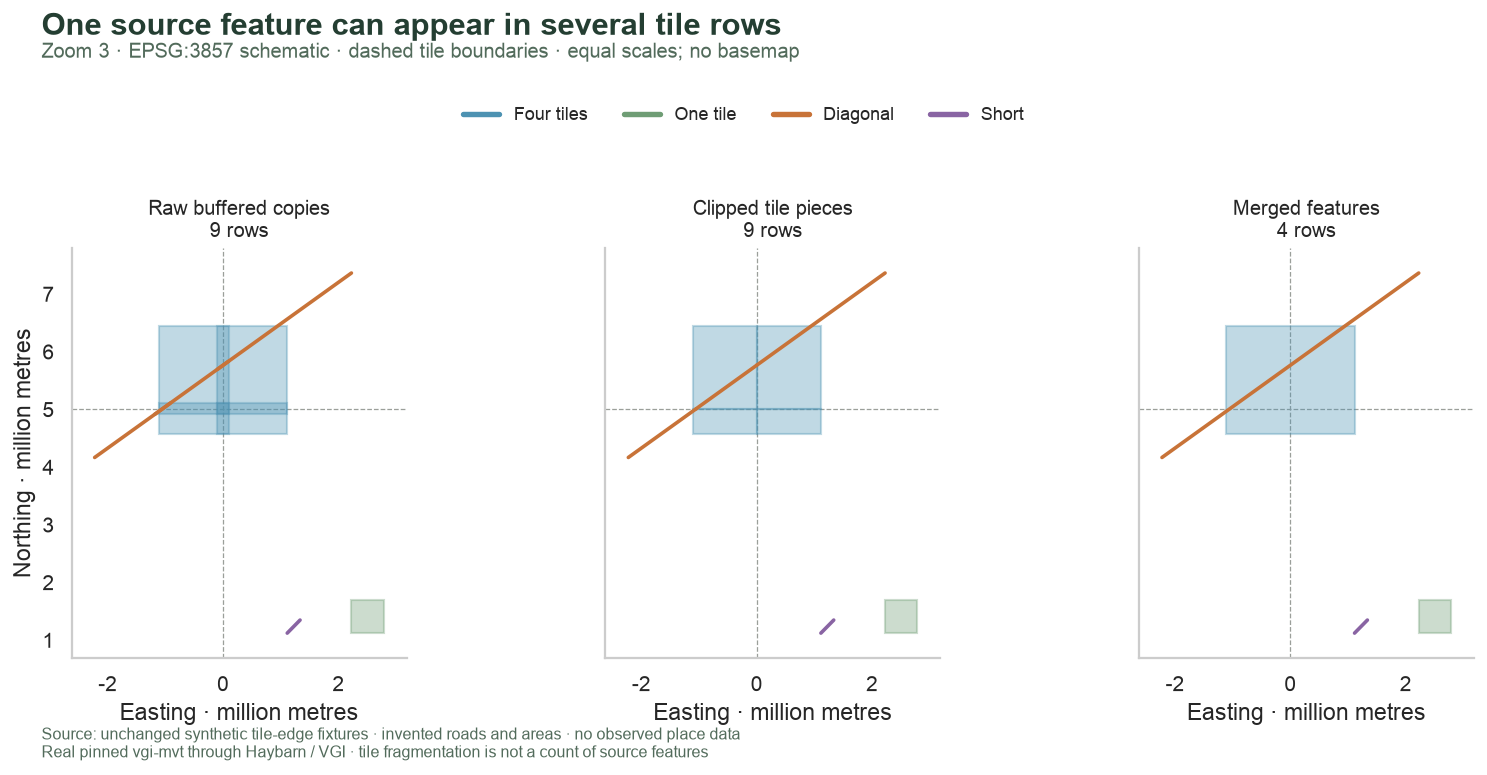

In [12]:
colors = {"Four tiles": "#4d92b2", "One tile": "#6f9d75", "Diagonal": "#c87338", "Short": "#8964a3"}
limits = extents.iloc[0]
padx = (limits.xmax - limits.xmin) * 0.08
pady = (limits.ymax - limits.ymin) * 0.07
fig, axes = plt.subplots(1, 3, figsize=(13.5, 6), sharex=True, sharey=True)
for ax, mode, title in zip(
    axes, ["raw", "clip", "merge"], ["Raw buffered copies", "Clipped tile pieces", "Merged features"], strict=True
):
    subset = shapes[shapes["mode"] == mode]
    for row in subset.itertuples():
        draw_geometry(ax, json.loads(row.geojson), colors[row.name])
    for x in set(tile_bounds.west).union(tile_bounds.east):
        ax.axvline(x, color="#9b9f9a", linestyle="--", linewidth=0.7, zorder=0)
    for y in set(tile_bounds.south).union(tile_bounds.north):
        ax.axhline(y, color="#9b9f9a", linestyle="--", linewidth=0.7, zorder=0)
    ax.set_title(f"{title}\n{len(subset)} rows", fontsize=11)
    ax.set_xlim(limits.xmin - padx, limits.xmax + padx)
    ax.set_ylim(limits.ymin - pady, limits.ymax + pady)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1e6:g}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1e6:g}"))
    ax.set_xlabel("Easting · million metres")
axes[0].set_ylabel("Northing · million metres")
fig.legend(
    [Line2D([0], [0], color=color, lw=3) for color in colors.values()],
    list(colors),
    loc="upper center",
    bbox_to_anchor=(0.5, 0.88),
    ncol=4,
    frameon=False,
    fontsize=10,
)
finish(
    fig,
    f"edge-modes-z{ZOOM}",
    "One source feature can appear in several tile rows",
    f"Zoom {ZOOM} · EPSG:3857 schematic · dashed tile boundaries · equal scales; no basemap",
    top=0.78,
)

## Measure the accounting difference

Compare row counts by layer, then normalize each layer’s projected measure to its merged value. This keeps road length separate from polygon area. It is not a comparison of ground area or road distance.

The worker also snaps nearby line endpoints at tile edges when merging. Thus clipped and merged line lengths need not be exactly equal, even though clipping has already removed the buffers. We report that difference rather than assuming preservation.

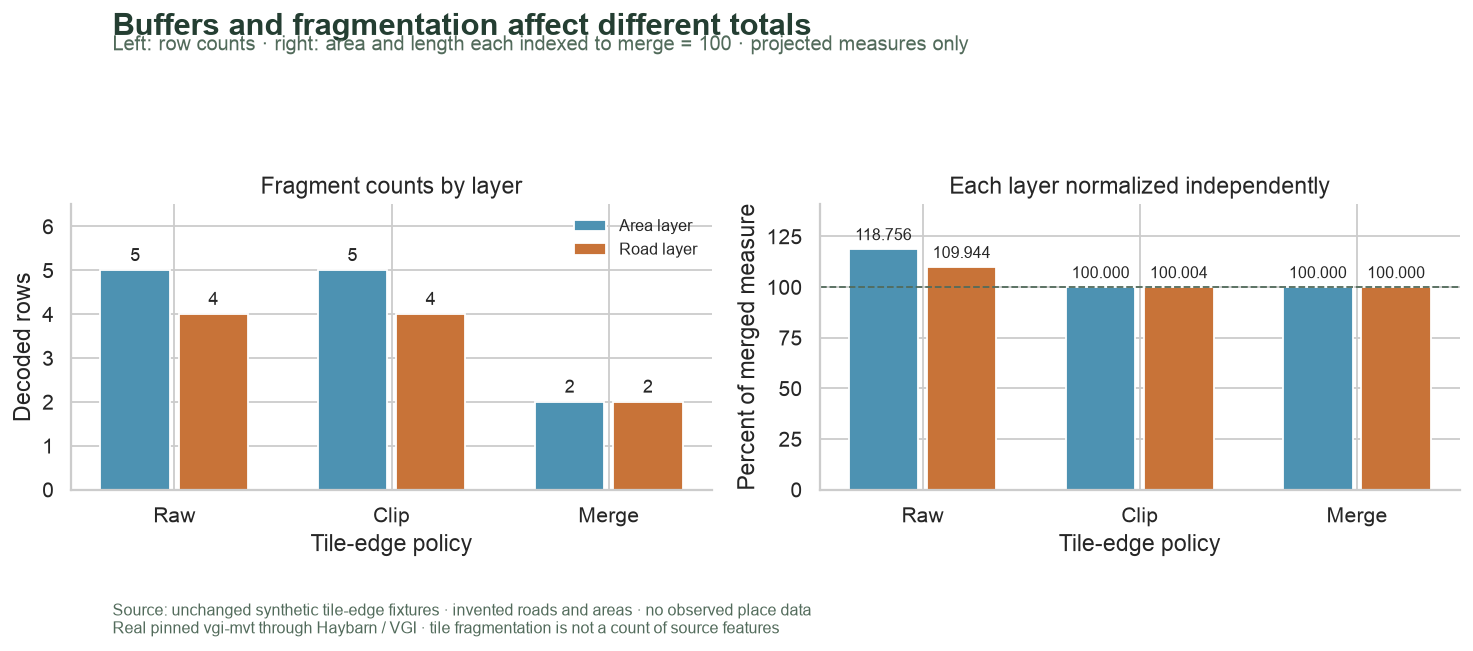

In [13]:
modes = ["raw", "clip", "merge"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for layer, offset, color, label in [
    ("areas", -0.18, "#4d92b2", "Area layer"),
    ("roads", 0.18, "#c87338", "Road layer"),
]:
    group = summary[summary.layer == layer].set_index("mode").loc[modes]
    x = [i + offset for i in range(3)]
    bars = axes[0].bar(x, group.rows, width=0.32, color=color, label=label)
    axes[0].bar_label(bars, padding=3, fontsize=10)
    bars = axes[1].bar(x, group.percent_of_merged, width=0.32, color=color, label=label)
    axes[1].bar_label(bars, labels=[f"{v:.3f}" for v in group.percent_of_merged], padding=3, fontsize=9)
axes[0].set_ylabel("Decoded rows")
axes[0].set_title("Fragment counts by layer")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_ylim(0, float(summary.rows.max()) + 1.5)
axes[1].set_ylabel("Percent of merged measure")
axes[1].set_title("Each layer normalized independently")
axes[1].axhline(100, color="#526b5b", linestyle="--", linewidth=1)
axes[1].set_ylim(0, float(summary.percent_of_merged.max()) + 22)
for ax in axes:
    ax.set_xticks(range(3), ["Raw", "Clip", "Merge"])
    ax.set_xlabel("Tile-edge policy")
axes[0].legend(loc="upper right", frameon=False, fontsize=9)
finish(
    fig,
    f"accounting-z{ZOOM}",
    "Buffers and fragmentation affect different totals",
    "Left: row counts · right: area and length each indexed to merge = 100 · projected measures only",
)

In [14]:
raw = summary[summary["mode"] == "raw"]
merged = summary[summary["mode"] == "merge"]
clip = summary[summary["mode"] == "clip"]
raw_area = float(raw.loc[raw.layer == "areas", "percent_of_merged"].iloc[0]) - 100
raw_length = float(raw.loc[raw.layer == "roads", "percent_of_merged"].iloc[0]) - 100
road_delta = float(
    clip.loc[clip.layer == "roads", "projected_measure"].iloc[0]
    - merged.loc[merged.layer == "roads", "projected_measure"].iloc[0]
)
if abs(road_delta) < 1e-6:
    road_delta = 0.0
display(
    Markdown(
        f"At zoom **{ZOOM}**, raw has **{int(raw.rows.sum())} rows** and merge has **{int(merged.rows.sum())} rows**. "
        f"Raw projected area is **{raw_area:.3f}%** above merged area; "
        f"raw projected road length is **{raw_length:.3f}%** above merged length. "
        f"Clipped minus merged road length is **{road_delta:,.3f} projected metres**. "
        "Endpoint snapping during merge is a documented reason not to demand exact line-length equality. "
        "These are properties of a tiny quantized display fixture, not estimates of real infrastructure."
    )
)

At zoom **3**, raw has **9 rows** and merge has **4 rows**. Raw projected area is **18.756%** above merged area; raw projected road length is **9.944%** above merged length. Clipped minus merged road length is **248.364 projected metres**. Endpoint snapping during merge is a documented reason not to demand exact line-length equality. These are properties of a tiny quantized display fixture, not estimates of real infrastructure.

## Check identity, geometry and accounting

Validate source-key coverage and the fixture’s no-ID condition, compare polygon area after clipping and merging with a relative floating-point tolerance, and report line measures without an unjustified exact-equality assertion. The no-ID merge behavior demonstrated here is specific to adjoining pieces with matching properties.

In [15]:
%%sql checks <<
SELECT 'every returned row uses the requested zoom' AS check_name,bool_and(z={{ZOOM}}) AS passed FROM features
UNION ALL SELECT 'geometries are present nonempty and valid',bool_and(geometry IS NOT NULL AND NOT ST_IsEmpty(geometry) AND ST_IsValid(geometry)) FROM features
UNION ALL SELECT 'source fixture names uniquely identify features',count(*)=count(DISTINCT(layer,name)) FROM source_keys
UNION ALL SELECT 'fixture has no encoded feature IDs',count(feature_id)=0 FROM features
UNION ALL SELECT 'every mode covers exactly the source keys',count(*)=0 FROM (
 (SELECT mode,layer,properties->>'$.name' AS name FROM features EXCEPT
  SELECT mode,layer,name FROM (VALUES('raw'),('clip'),('merge')) m(mode) CROSS JOIN source_keys)
 UNION ALL
 (SELECT mode,layer,name FROM (VALUES('raw'),('clip'),('merge')) m(mode) CROSS JOIN source_keys EXCEPT
  SELECT mode,layer,properties->>'$.name' AS name FROM features))
UNION ALL SELECT 'merged fixture has one row per source feature',count(*)=count(DISTINCT(layer,properties->>'$.name')) FROM features WHERE mode='merge'
UNION ALL SELECT 'projected measurements are finite and positive',bool_and(isfinite(projected_measure) AND projected_measure>0) FROM accounting
UNION ALL SELECT 'clipped and merged polygon area agree within tolerance',
 abs(c.projected_measure-m.projected_measure)<=1e-9*greatest(1,m.projected_measure)
 FROM accounting c JOIN accounting m USING(layer) WHERE c.layer='areas' AND c.mode='clip' AND m.mode='merge'
UNION ALL SELECT 'raw sums include at least clipped measure in this fixture',bool_and(r.projected_measure+1e-6>=c.projected_measure)
 FROM accounting r JOIN accounting c USING(layer) WHERE r.mode='raw' AND c.mode='clip'
UNION ALL SELECT 'merged fixture row counts do not exceed clipped counts',bool_and(m.rows<=c.rows)
 FROM accounting m JOIN accounting c USING(layer) WHERE m.mode='merge' AND c.mode='clip';

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
display(
    Markdown(
        f"All **{len(checks)} checks** pass. "
        "Tile rows, source-feature identity and projected measures now have separate accounting."
    )
)

,check_name,passed
0,every returned row uses the requested zoom,True
1,geometries are present nonempty and valid,True
2,source fixture names uniquely identify features,True
3,fixture has no encoded feature IDs,True
4,every mode covers exactly the source keys,True
5,merged fixture has one row per source feature,True
6,projected measurements are finite and positive,True
7,clipped and merged polygon area agree within t...,True
8,raw sums include at least clipped measure in t...,True
9,merged fixture row counts do not exceed clippe...,True


All **10 checks** pass. Tile rows, source-feature identity and projected measures now have separate accounting.

## Try one change

Change `ZOOM` from **3** to **2**, restart and run all. Predict fewer tile fragments because the lower-zoom tiles are larger; compare both charts and the raw-versus-merged row counts. The four labeled source features should remain covered, but exact geometry measurements can change with quantization and simplification. Inspect the clipped-minus-merged line difference too. Restore **3** for the saved default.

In [17]:
connection.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>